# Branch E-I Tuning: Operating Points Across ImageNet Classes

For each dendritic branch, every image presentation drives it to a specific
operating point in (E, I) space — the excitatory current on the y-axis and
inhibitory current on the x-axis.  Taking 100 draws per class lets us see:

- **Selectivity**: do different classes drive distinct (E,I) clouds?
- **Trial variability**: how tight is each class cloud (precision of tuning)?
- **E-I balance**: do branches track E~I (balanced) or operate off-diagonal?
- **Scaling**: how does the operating point shift with N_E or morphology?

All of this requires loading the trained model and running short inference passes —
it cannot be done from the `performance/final.json` files alone.

In [1]:
import sys, os, glob, json
import numpy as np
import torch
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from torch.utils.data import DataLoader, Subset

sys.path.insert(0, '/n/home13/adithyavm/dendritic-modeling/src')

from dendritic_modeling.config import load_config
from dendritic_modeling.scripts.script_utils.setup_utils import initialize_model
from dendritic_modeling.datasets.standard_datasets import load_imagenet_as_datasets
from dendritic_modeling.networks import DendriticBranchLayer

print('imports OK')

imports OK


In [2]:
# ── paths ────────────────────────────────────────────────────────────────────
OUTPUTS_DIRS = [
    '/n/holylfs06/LABS/kempner_project_b/Lab/dendritic/adivm/dendritic-modeling/outputs',
    '/n/home13/adithyavm/dendritic-modeling/outputs',
]
IMAGENET_PATH = '/n/holylfs06/LABS/kempner_shared/Everyone/testbed/vision/imagenet_1k'
CONFIGS_DIR   = '/n/home13/adithyavm/dendritic-modeling/configs/vision'

# ── sweep parameters ─────────────────────────────────────────────────────────
N_E_VALUES = [256, 512, 1024, 2048, 4096]

# Map each (morphology, N_E) → (output_glob, config_yaml)
MODEL_REGISTRY = {
    ('2x2',   ne): (f'alexnet_k1_ne{ne}_noproj_ddp_*',        f'{CONFIGS_DIR}/alexnet_k1_ne{ne}_noproj_ddp.yaml')
    for ne in N_E_VALUES
}
MODEL_REGISTRY.update({
    ('3x3x3', ne): (f'alexnet_k1_ne{ne}_3x3x3_noproj_ddp_*',  f'{CONFIGS_DIR}/alexnet_k1_ne{ne}_3x3x3_noproj_ddp.yaml')
    for ne in N_E_VALUES
})

# ── analysis parameters ───────────────────────────────────────────────────────
N_CLASSES    = 20     # ImageNet classes to sample from (first N by index)
N_SAMPLES    = 100    # draws per class
BATCH_SIZE   = 64
DEVICE       = 'cuda' if torch.cuda.is_available() else 'cpu'

# branches to highlight in multi-branch plots (indices into the leaf-layer output)
# these correspond to different leaf dendrites of the first few neurons
BRANCH_INDICES = [0, 1, 2, 3]   # first 4 leaf branches (all from neuron 0 in a 2x2 tree)

print(f'device: {DEVICE}')
print(f'models registered: {len(MODEL_REGISTRY)}')

device: cpu
models registered: 10


In [3]:
def find_run_dir(glob_pattern):
    """Return the most recent output directory matching the pattern."""
    for outputs in OUTPUTS_DIRS:
        found = sorted(glob.glob(f'{outputs}/{glob_pattern}'))
        if found:
            return found[-1]
    return None


def load_model(run_dir, config_path):
    """Reconstruct model from config, load trained weights."""
    config = load_config(config_path)
    model, _ = initialize_model(config.model)
    ckpt = torch.load(f'{run_dir}/final_model.pt', map_location='cpu', weights_only=False)
    sd   = ckpt.get('model_state_dict', ckpt)
    model.load_state_dict(sd)
    model.eval()
    return model


def collect_branch_activations(model, loader, device):
    """
    Run inference and capture (E, I) synaptic currents at every
    DendriticBranchLayer in the excitatory cell pathway.

    Returns
    -------
    dict: layer_name → {'exc': ndarray [N, B], 'inh': ndarray [N, B]}
         where N = total samples, B = number of branches at that level.
         Layers are ordered leaf → soma.
    """
    store = {}   # layer_name → {'exc': list[tensor], 'inh': list[tensor]}

    def make_hook(name):
        def hook(module, inp, _output):
            x_exc, x_inh, _x_branch = inp
            entry = store.setdefault(name, {'exc': [], 'inh': []})
            if module.branch_excitation is not None:
                entry['exc'].append(module.branch_excitation(x_exc).detach().cpu())
            if module.branch_inhibition is not None and x_inh is not None:
                entry['inh'].append(module.branch_inhibition(x_inh).detach().cpu())
        return hook

    handles = []
    for name, mod in model.named_modules():
        if isinstance(mod, DendriticBranchLayer) and 'excitatory_cells' in name:
            handles.append(mod.register_forward_hook(make_hook(name)))

    model.to(device)
    with torch.no_grad():
        for batch_x, _ in loader:
            model(batch_x.to(device))

    for h in handles:
        h.remove()
    model.cpu()

    # concatenate batches → numpy
    result = {}
    for lname, tensors in store.items():
        result[lname] = {
            k: torch.cat(v, dim=0).numpy()
            for k, v in tensors.items() if v
        }
    return result


print('helpers defined')

helpers defined


In [4]:
# Load ImageNet validation set once (shared across all models)
_, _, val_ds = load_imagenet_as_datasets(
    train_valid_split=0.8,
    flatten=False,
    normalize=True,
    task_data_path=IMAGENET_PATH,
)

# Build class → sample index mapping
targets = np.array(val_ds.targets if hasattr(val_ds, 'targets')
                   else [val_ds.dataset.targets[i] for i in val_ds.indices])

class_to_idxs = {}
for i, t in enumerate(targets):
    class_to_idxs.setdefault(int(t), []).append(i)

selected_classes = sorted(class_to_idxs.keys())[:N_CLASSES]
print(f'selected {len(selected_classes)} classes: {selected_classes}')

# Build a stratified subset: N_SAMPLES per class, in class order
all_idxs   = []
all_labels = []
for c in selected_classes:
    idxs = class_to_idxs[c][:N_SAMPLES]
    all_idxs.extend(idxs)
    all_labels.extend([c] * len(idxs))

all_labels = np.array(all_labels)
subset     = Subset(val_ds, all_idxs)
loader     = DataLoader(subset, batch_size=BATCH_SIZE, shuffle=False, num_workers=4)

print(f'dataset: {len(subset)} samples  ({N_SAMPLES} × {N_CLASSES} classes)')

selected 20 classes: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
dataset: 1000 samples  (100 × 20 classes)


In [5]:
# ── start with the smallest, fastest model to validate the pipeline ───────────
morph, ne = '2x2', 256
glob_pat, cfg_path = MODEL_REGISTRY[(morph, ne)]

run_dir = find_run_dir(glob_pat)
print(f'run dir: {run_dir}')
assert run_dir is not None, f'no run found for {glob_pat}'

model = load_model(run_dir, cfg_path)
print('model loaded')

acts = collect_branch_activations(model, loader, DEVICE)

# show layer names and output shapes
for lname, d in acts.items():
    shapes = {k: v.shape for k, v in d.items()}
    print(f'  {lname.split(".")[-3]:20s}  {shapes}')

run dir: /n/holylfs06/LABS/kempner_project_b/Lab/dendritic/adivm/dendritic-modeling/outputs/alexnet_k1_ne256_noproj_ddp_20260416_081458
INFO pretrained.py:497  Built split plan:
BackboneSplitPlan(backbone='alexnet', spatial=False)
  prefix  (16 layers): ['features.0', 'features.1', 'features.2', 'features.3', 'features.4', 'features.5', 'features.6', 'features.7', 'features.8', 'features.9', 'features.10', 'features.11', 'features.12', 'avgpool', 'classifier.1', 'classifier.2']
  replace (2 layers): ['classifier.4', 'classifier.5']
  suffix  (1 layers): ['classifier.6']
  prefix_output_dim=4096
  suffix_input_dim=4096
  suffix_output_dim=1000
INFO config_utils.py:112  Converting DictConfig to dict for EINet initialization (this should happen only once)
INFO setup_utils.py:447  Initialized model: Classifier
model loaded
  excitatory_cells      {'exc': (1000, 1024), 'inh': (1000, 1024)}
  excitatory_cells      {'exc': (1000, 512), 'inh': (1000, 512)}
  excitatory_cells      {}


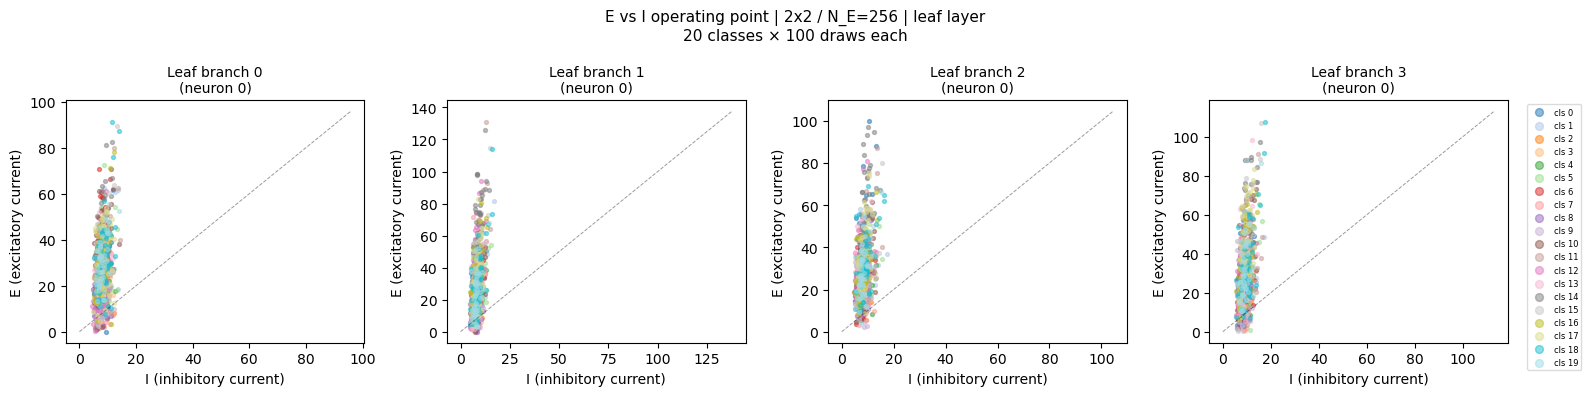

In [6]:
# ── Figure 1: E vs I for 4 leaf branches of neuron 0, 2x2 / N_E=256 ───────────
#
# Each panel = one leaf branch.  Each colour = one ImageNet class.
# 100 dots per colour = trial-to-trial variability within a class.
# Tight cluster → precise tuning.  Separated clouds → class selectivity.
# The diagonal E=I line marks where shunting halves the input (Vout = 0.5).

leaf_layer = sorted(acts.keys())[0]          # branch_layers.0  (most distal)
exc_all = acts[leaf_layer].get('exc')        # [N_total, N_leaf_branches]
inh_all = acts[leaf_layer].get('inh')        # [N_total, N_leaf_branches] or None

if exc_all is None:
    print('no excitatory data captured — check layer name filter')
else:
    colors = cm.tab20(np.linspace(0, 1, N_CLASSES))
    n_panels = min(len(BRANCH_INDICES), 4)
    fig, axes = plt.subplots(1, n_panels, figsize=(4*n_panels, 4), squeeze=False)

    for panel_i, branch_b in enumerate(BRANCH_INDICES[:n_panels]):
        ax = axes[0, panel_i]

        for c_i, c in enumerate(selected_classes):
            mask = all_labels == c
            e = exc_all[mask, branch_b]
            i = inh_all[mask, branch_b] if inh_all is not None else np.zeros_like(e)
            ax.scatter(i, e, color=colors[c_i], alpha=0.5, s=8, label=f'cls {c}')

        # diagonal E=I guide line
        lim = max(ax.get_xlim()[1], ax.get_ylim()[1])
        ax.plot([0, lim], [0, lim], 'k--', lw=0.7, alpha=0.4)

        ax.set_xlabel('I (inhibitory current)', fontsize=10)
        ax.set_ylabel('E (excitatory current)', fontsize=10)
        ax.set_title(f'Leaf branch {branch_b}\n(neuron {branch_b // 4})', fontsize=10)

    axes[0, -1].legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=6,
                       markerscale=2, framealpha=0.7)
    fig.suptitle(f'E vs I operating point | {morph} / N_E={ne} | leaf layer\n'
                 f'{N_CLASSES} classes × {N_SAMPLES} draws each', fontsize=11)
    plt.tight_layout()
    plt.savefig('branch_ei_single_model.png', dpi=150, bbox_inches='tight')
    plt.show()

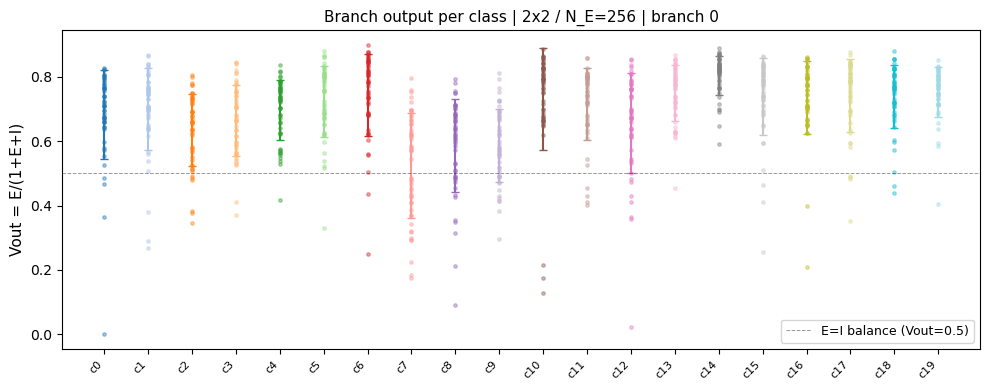

: 

In [ ]:
# ── Figure 2: Vout = E/(1+E+I) distribution per class, one branch ─────────────
#
# Bernardo-style question: is the OUTPUT of a branch class-selective,
# or does shunting normalise away the class-specific E-I variation?

branch_b = 0
e = exc_all[:, branch_b]
i = inh_all[:, branch_b] if inh_all is not None else np.zeros_like(e)
vout = e / (1.0 + e + i + 1e-8)

fig, ax = plt.subplots(figsize=(10, 4))
for c_i, c in enumerate(selected_classes):
    mask = all_labels == c
    ax.scatter([c_i]*mask.sum(), vout[mask],
               color=colors[c_i], alpha=0.4, s=6)
    ax.errorbar(c_i, vout[mask].mean(), yerr=vout[mask].std(),
                color=colors[c_i], capsize=3, lw=1.5)

ax.set_xticks(range(N_CLASSES))
ax.set_xticklabels([f'c{c}' for c in selected_classes], rotation=45, ha='right', fontsize=8)
ax.set_ylabel('Vout = E/(1+E+I)', fontsize=11)
ax.set_title(f'Branch output per class | {morph} / N_E={ne} | branch {branch_b}', fontsize=11)
ax.axhline(0.5, color='k', lw=0.7, ls='--', alpha=0.4, label='E=I balance (Vout=0.5)')
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig('branch_vout_per_class.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# ── Figure 3: E vs I across N_E sweep, fixed morphology ───────────────────────
#
# Shows how the operating point shifts as the E population grows.
# Each subplot = one N_E value.  Same branch, same classes throughout.
# Question: does more E capacity push operating points higher, lower, or stay put?

sweep_morph = '2x2'
branch_b    = 0

fig, axes = plt.subplots(1, len(N_E_VALUES), figsize=(4*len(N_E_VALUES), 4), sharey=False)

for ax, ne in zip(axes, N_E_VALUES):
    glob_pat, cfg_path = MODEL_REGISTRY[(sweep_morph, ne)]
    run_dir = find_run_dir(glob_pat)
    if run_dir is None:
        ax.set_title(f'N_E={ne}\n(missing)')
        continue

    m = load_model(run_dir, cfg_path)
    a = collect_branch_activations(m, loader, DEVICE)
    del m

    leaf = sorted(a.keys())[0]
    e_all = a[leaf].get('exc')
    i_all = a[leaf].get('inh')
    if e_all is None:
        ax.set_title(f'N_E={ne}\n(no exc data)')
        continue

    for c_i, c in enumerate(selected_classes):
        mask = all_labels == c
        e = e_all[mask, branch_b]
        i = i_all[mask, branch_b] if i_all is not None else np.zeros_like(e)
        ax.scatter(i, e, color=colors[c_i], alpha=0.45, s=6)

    lim = max(ax.get_xlim()[1], ax.get_ylim()[1])
    ax.plot([0, lim], [0, lim], 'k--', lw=0.7, alpha=0.4)
    ax.set_xlabel('I', fontsize=9)
    ax.set_ylabel('E', fontsize=9)
    ax.set_title(f'N_E={ne}', fontsize=10)

fig.suptitle(f'E-I operating point vs N_E | {sweep_morph} noproj | branch {branch_b}\n'
             f'{N_CLASSES} classes × {N_SAMPLES} draws', fontsize=11)
plt.tight_layout()
plt.savefig('branch_ei_ne_sweep.png', dpi=150, bbox_inches='tight')
plt.show()

INFO pretrained.py:497  Built split plan:
BackboneSplitPlan(backbone='alexnet', spatial=False)
  prefix  (16 layers): ['features.0', 'features.1', 'features.2', 'features.3', 'features.4', 'features.5', 'features.6', 'features.7', 'features.8', 'features.9', 'features.10', 'features.11', 'features.12', 'avgpool', 'classifier.1', 'classifier.2']
  replace (2 layers): ['classifier.4', 'classifier.5']
  suffix  (1 layers): ['classifier.6']
  prefix_output_dim=4096
  suffix_input_dim=4096
  suffix_output_dim=1000
INFO config_utils.py:112  Converting DictConfig to dict for EINet initialization (this should happen only once)
INFO setup_utils.py:447  Initialized model: Classifier
INFO pretrained.py:497  Built split plan:
BackboneSplitPlan(backbone='alexnet', spatial=False)
  prefix  (16 layers): ['features.0', 'features.1', 'features.2', 'features.3', 'features.4', 'features.5', 'features.6', 'features.7', 'features.8', 'features.9', 'features.10', 'features.11', 'features.12', 'avgpool', 'cl

In [ ]:
# ── Figure 4: 2x2 vs 3x3x3, same N_E, multiple branches ──────────────────────
#
# Rows = morphology (2x2, 3x3x3).  Columns = branch index.
# Question: does finer branching produce more class-selective operating points?

compare_ne = 256
compare_branches = [0, 1, 2, 3]
morphologies = ['2x2', '3x3x3']

fig, axes = plt.subplots(len(morphologies), len(compare_branches),
                          figsize=(4*len(compare_branches), 4*len(morphologies)))

morph_acts = {}
for morph in morphologies:
    glob_pat, cfg_path = MODEL_REGISTRY[(morph, compare_ne)]
    run_dir = find_run_dir(glob_pat)
    if run_dir is None:
        print(f'missing: {morph} ne={compare_ne}')
        morph_acts[morph] = None
        continue
    m = load_model(run_dir, cfg_path)
    morph_acts[morph] = collect_branch_activations(m, loader, DEVICE)
    del m

for row, morph in enumerate(morphologies):
    a = morph_acts.get(morph)
    for col, branch_b in enumerate(compare_branches):
        ax = axes[row, col]
        if a is None:
            ax.set_title(f'{morph} missing')
            continue

        leaf = sorted(a.keys())[0]
        e_all = a[leaf].get('exc')
        i_all = a[leaf].get('inh')

        for c_i, c in enumerate(selected_classes):
            mask = all_labels == c
            e = e_all[mask, branch_b]
            i = i_all[mask, branch_b] if i_all is not None else np.zeros_like(e)
            ax.scatter(i, e, color=colors[c_i], alpha=0.45, s=6)

        lim = max(ax.get_xlim()[1], ax.get_ylim()[1])
        ax.plot([0, lim], [0, lim], 'k--', lw=0.7, alpha=0.4)
        ax.set_title(f'{morph}  branch {branch_b}', fontsize=9)
        ax.set_xlabel('I', fontsize=8)
        ax.set_ylabel('E', fontsize=8)

fig.suptitle(f'Morphology comparison | N_E={compare_ne}\n'
             f'{N_CLASSES} classes × {N_SAMPLES} draws each', fontsize=11)
plt.tight_layout()
plt.savefig('branch_ei_morph_compare.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# ── Figure 5: Quantify class selectivity per branch ────────────────────────────
#
# Selectivity index: variance of class-mean Vout / total variance of Vout.
# SI = 1 → all variance is between classes (perfectly selective).
# SI = 0 → within-class variance dominates (no class selectivity).
# Plot SI for every leaf branch, ordered.  Are there 'expert' branches?

def selectivity_index(exc_arr, inh_arr, labels, classes):
    """Per-branch selectivity index (eta-squared / omega-squared analog)."""
    if inh_arr is None:
        inh_arr = np.zeros_like(exc_arr)
    vout = exc_arr / (1.0 + exc_arr + inh_arr + 1e-8)  # [N, B]
    N, B = vout.shape
    class_means = np.array([vout[labels == c].mean(axis=0) for c in classes])  # [C, B]
    grand_mean  = vout.mean(axis=0)                                             # [B]
    ss_between  = sum(((labels == c).sum() * (class_means[i] - grand_mean)**2)
                      for i, c in enumerate(classes))                           # [B]
    ss_total    = ((vout - grand_mean)**2).sum(axis=0)                          # [B]
    return ss_between / (ss_total + 1e-10)


# Compute for the already-loaded 2x2/256 activations
leaf = sorted(acts.keys())[0]
si = selectivity_index(
    acts[leaf].get('exc'),
    acts[leaf].get('inh'),
    all_labels,
    selected_classes,
)

fig, ax = plt.subplots(figsize=(12, 3))
ax.bar(np.arange(len(si)), np.sort(si)[::-1], width=1.0, color='steelblue', alpha=0.8)
ax.set_xlabel('Branch index (sorted by selectivity)', fontsize=10)
ax.set_ylabel('Selectivity index (η²)', fontsize=10)
ax.set_title(f'Class selectivity of leaf branches | {morph} / N_E={ne}\n'
             f'η² = between-class Vout variance / total Vout variance', fontsize=10)
ax.axhline(1/N_CLASSES, color='r', ls='--', lw=1, label=f'chance (1/{N_CLASSES})')
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig('branch_selectivity_index.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'Median SI: {np.median(si):.3f} | Max SI: {np.max(si):.3f} | '
      f'Branches above chance: {(si > 1/N_CLASSES).mean()*100:.1f}%')

In [ ]:
# ── Figure 6: Median selectivity index across entire N_E × morphology sweep ───
#
# One number per model: what fraction of leaf-branch Vout variance
# is explained by class identity?

sweep_results = {}  # (morph, ne) → median_SI

for (morph, ne), (glob_pat, cfg_path) in MODEL_REGISTRY.items():
    run_dir = find_run_dir(glob_pat)
    if run_dir is None:
        print(f'skip {morph}/{ne}: no run')
        continue
    try:
        m   = load_model(run_dir, cfg_path)
        a   = collect_branch_activations(m, loader, DEVICE)
        del m
        leaf = sorted(a.keys())[0]
        si  = selectivity_index(
            a[leaf].get('exc'), a[leaf].get('inh'), all_labels, selected_classes
        )
        sweep_results[(morph, ne)] = np.median(si)
        print(f'{morph:6s}  N_E={ne:4d}  median_SI={np.median(si):.4f}')
    except Exception as exc:
        print(f'error {morph}/{ne}: {exc}')

fig, ax = plt.subplots(figsize=(8, 4))
for morph, marker, color in [('2x2', 's', 'darkorange'), ('3x3x3', 'o', 'steelblue')]:
    xs = [ne for (m, ne) in sweep_results if m == morph]
    ys = [sweep_results[(morph, ne)] for ne in xs]
    order = np.argsort(xs)
    ax.plot([xs[o] for o in order], [ys[o] for o in order],
            marker=marker, color=color, label=morph)

ax.axhline(1/N_CLASSES, color='r', ls='--', lw=0.8, label=f'chance (1/{N_CLASSES})')
ax.set_xscale('log', base=2)
ax.set_xticks(N_E_VALUES)
ax.set_xticklabels(N_E_VALUES)
ax.set_xlabel('N_E', fontsize=11)
ax.set_ylabel('Median leaf-branch selectivity (η²)', fontsize=11)
ax.set_title(f'Class selectivity of leaf branches across sweep\n'
             f'({N_CLASSES} classes × {N_SAMPLES} draws)', fontsize=11)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('branch_selectivity_sweep.png', dpi=150, bbox_inches='tight')
plt.show()